# Segmentasi Citra dan Morphological Processing

Notebook ini memproses menganalisis 3 gambar menggunakan thresholding dan operasi morfologi: dilation, erosion, opening, dan closing.

Nama : Andika Wahyu Dwi Saputra

NIM : 25/557982/PA/23452

## Input Gambar

Pada percobaan ini, menggunakan 3 input gambar berformat bmp yaitu sel darah, bentuk daun, dan gambar popcorn.

## Pengaturan nama file dan threshold

- `OBJEK_GELAP = False`: objek yang lebih terang dari threshold menjadi putih.
- `OBJEK_GELAP = True`: objek yang lebih gelap dari threshold menjadi putih.



In [61]:
NAMA_FILE_1 = "sample3.bmp"
NAMA_FILE_2 = "sample7.bmp"
NAMA_FILE_3 = "sample10.bmp"

THRESHOLD_1 = 127
THRESHOLD_2 = 127
THRESHOLD_3 = 127

OBJEK_GELAP_1 = False
OBJEK_GELAP_2 = True
OBJEK_GELAP_3 = False

print("Input 1:", NAMA_FILE_1)
print("Input 2:", NAMA_FILE_2)
print("Input 3:", NAMA_FILE_3)

Input 1: sample3.bmp
Input 2: sample7.bmp
Input 3: sample10.bmp


## Membaca gambar dan mengubahnya menjadi grayscale

Setiap piksel warna diubah menjadi satu nilai keabuan dari 0 sampai 255.

Rumus grayscale:

\[
I_{gray}=0.299R+0.587G+0.114B
\]

`R` adalah merah, `G` adalah hijau, dan `B` adalah biru. Nilai 0 berarti hitam, sedangkan 255 berarti putih.

In [62]:
def baca_bmp(nama_file):
    with open(nama_file, "rb") as file:
        data = file.read()

    if data[0:2] != b"BM":
        raise ValueError(nama_file + " bukan file BMP.")

    offset = int.from_bytes(data[10:14], "little")
    lebar = int.from_bytes(data[18:22], "little", signed=True)
    tinggi_asli = int.from_bytes(data[22:26], "little", signed=True)
    jumlah_plane = int.from_bytes(data[26:28], "little")
    bit_pixel = int.from_bytes(data[28:30], "little")
    kompresi = int.from_bytes(data[30:34], "little")

    if lebar <= 0 or tinggi_asli == 0:
        raise ValueError("Ukuran gambar tidak valid: " + nama_file)

    if jumlah_plane != 1 or bit_pixel not in (24, 32) or kompresi != 0:
        raise ValueError(
            "Gunakan BMP 24-bit atau 32-bit tanpa kompresi: " + nama_file
        )

    tinggi = abs(tinggi_asli)
    byte_per_pixel = bit_pixel // 8
    ukuran_baris = ((lebar * byte_per_pixel + 3) // 4) * 4

    gambar_abu = []

    for y in range(tinggi):
        baris = []

        if tinggi_asli > 0:
            posisi_baris = tinggi - 1 - y
        else:
            posisi_baris = y

        for x in range(lebar):
            posisi = offset + posisi_baris * ukuran_baris + x * byte_per_pixel

            biru = data[posisi]
            hijau = data[posisi + 1]
            merah = data[posisi + 2]

            abu = int(0.299 * merah + 0.587 * hijau + 0.114 * biru)
            baris.append(abu)

        gambar_abu.append(baris)

    return gambar_abu


gambar_abu_1 = baca_bmp(NAMA_FILE_1)
gambar_abu_2 = baca_bmp(NAMA_FILE_2)
gambar_abu_3 = baca_bmp(NAMA_FILE_3)

print("Ketiga gambar berhasil dibaca.")
for nomor, gambar in enumerate(
    [gambar_abu_1, gambar_abu_2, gambar_abu_3], start=1
):
    print(
        "Gambar", nomor, ":",
        len(gambar[0]), "x", len(gambar), "piksel"
    )

Ketiga gambar berhasil dibaca.
Gambar 1 : 420 x 300 piksel
Gambar 2 : 554 x 554 piksel
Gambar 3 : 800 x 533 piksel


## Menampilkan tiga gambar grayscale

Ketiga gambar ditampilkan berdampingan untuk melihat kondisi awal sebelum segmentasi.

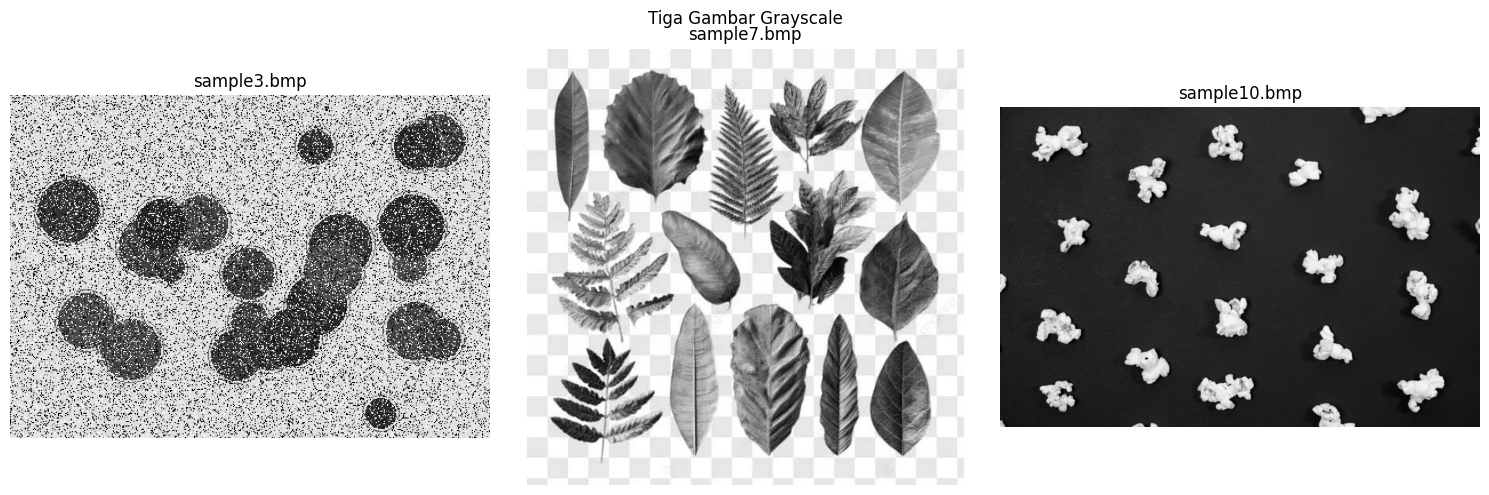

In [63]:
import matplotlib.pyplot as plt

def tampilkan_tiga(gambar1, gambar2, gambar3, judul, label1, label2, label3):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    daftar_gambar = [gambar1, gambar2, gambar3]
    daftar_label = [label1, label2, label3]

    for ax, gambar, label in zip(axes, daftar_gambar, daftar_label):
        ax.imshow(gambar, cmap="gray", vmin=0, vmax=255)
        ax.set_title(label)
        ax.axis("off")

    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()


tampilkan_tiga(
    gambar_abu_1, gambar_abu_2, gambar_abu_3,
    "Tiga Gambar Grayscale",
    NAMA_FILE_1, NAMA_FILE_2, NAMA_FILE_3
)

## Segmentasi menggunakan thresholding

Thresholding memisahkan objek dan latar belakang menjadi dua warna: putih (255) dan hitam (0).

Rumus untuk objek terang:

\[
B(x,y)=
\begin{cases}
255, & I(x,y)\geq T\\
0, & I(x,y)<T
\end{cases}
\]

`I(x,y)` adalah intensitas piksel dan `T` adalah nilai threshold. Untuk objek gelap, aturan dibalik.

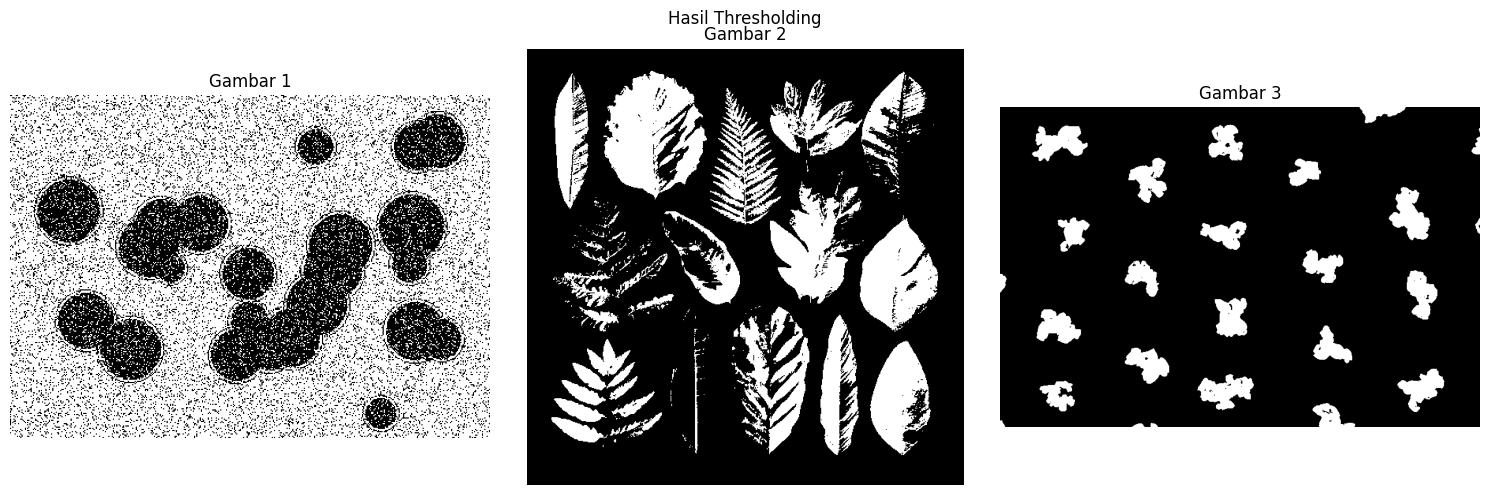

In [64]:
def thresholding(gambar, nilai_threshold, objek_gelap=False):
    tinggi = len(gambar)
    lebar = len(gambar[0])
    hasil = []

    for y in range(tinggi):
        baris = []

        for x in range(lebar):
            nilai = gambar[y][x]

            if objek_gelap:
                if nilai < nilai_threshold:
                    baris.append(255)
                else:
                    baris.append(0)
            else:
                if nilai >= nilai_threshold:
                    baris.append(255)
                else:
                    baris.append(0)

        hasil.append(baris)

    return hasil


hasil_segmentasi_1 = thresholding(gambar_abu_1, THRESHOLD_1, OBJEK_GELAP_1)
hasil_segmentasi_2 = thresholding(gambar_abu_2, THRESHOLD_2, OBJEK_GELAP_2)
hasil_segmentasi_3 = thresholding(gambar_abu_3, THRESHOLD_3, OBJEK_GELAP_3)

tampilkan_tiga(
    hasil_segmentasi_1, hasil_segmentasi_2, hasil_segmentasi_3,
    "Hasil Thresholding",
    "Gambar 1", "Gambar 2", "Gambar 3"
)

## Operasi dilation

Dilation memperbesar area objek putih. Program memeriksa area kernel 3 × 3 di sekitar setiap piksel. Jika ada minimal satu piksel putih di area tersebut, piksel hasil menjadi putih.

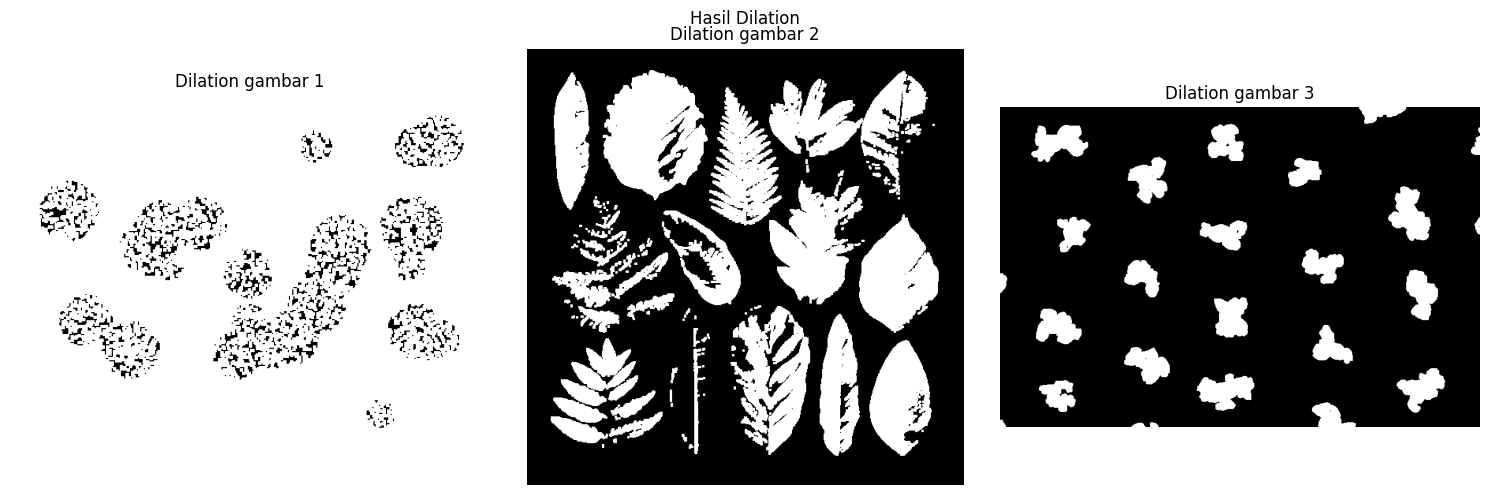

In [65]:
def dilasi(gambar):
    tinggi = len(gambar)
    lebar = len(gambar[0])
    hasil = [[0 for x in range(lebar)] for y in range(tinggi)]

    for y in range(tinggi):
        for x in range(lebar):
            ada_objek = False

            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny = y + dy
                    nx = x + dx

                    if 0 <= ny < tinggi and 0 <= nx < lebar:
                        if gambar[ny][nx] == 255:
                            ada_objek = True

            if ada_objek:
                hasil[y][x] = 255

    return hasil


hasil_dilasi_1 = dilasi(hasil_segmentasi_1)
hasil_dilasi_2 = dilasi(hasil_segmentasi_2)
hasil_dilasi_3 = dilasi(hasil_segmentasi_3)

tampilkan_tiga(
    hasil_dilasi_1, hasil_dilasi_2, hasil_dilasi_3,
    "Hasil Dilation",
    "Dilation gambar 1", "Dilation gambar 2", "Dilation gambar 3"
)

## Operasi erosion

Erosion memperkecil area objek putih. Piksel hasil tetap putih hanya jika seluruh piksel pada area 3 × 3 juga putih. Jika ada piksel hitam atau posisi berada di luar batas gambar, hasilnya menjadi hitam.

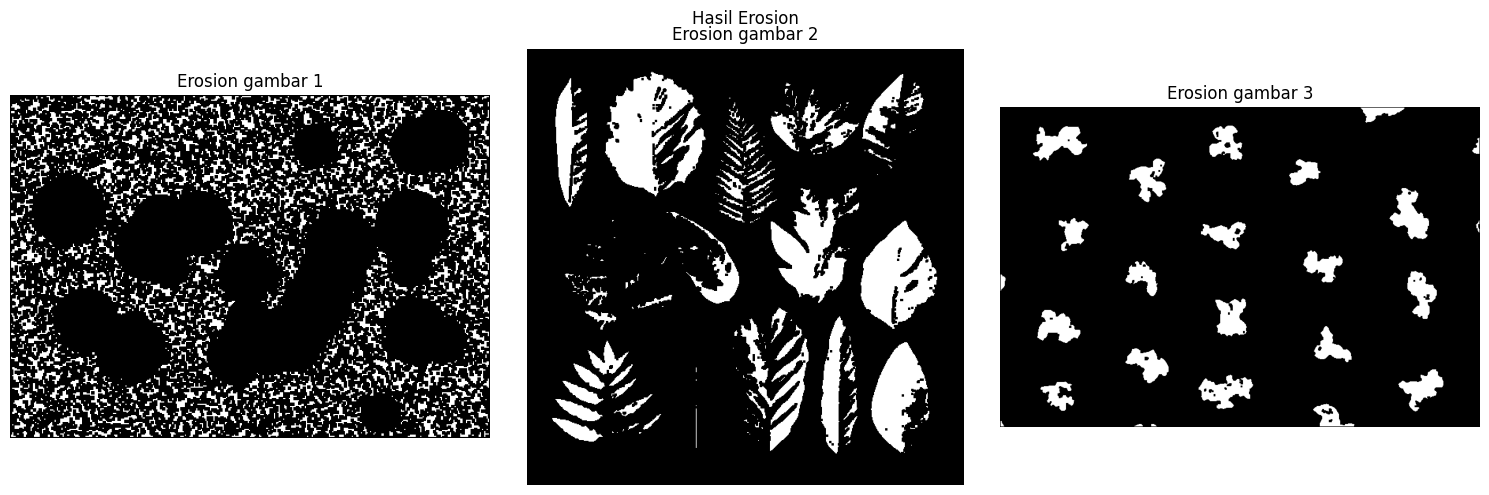

In [66]:
def erosi(gambar):
    tinggi = len(gambar)
    lebar = len(gambar[0])
    hasil = [[0 for x in range(lebar)] for y in range(tinggi)]

    for y in range(tinggi):
        for x in range(lebar):
            semua_putih = True

            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny = y + dy
                    nx = x + dx

                    if ny < 0 or ny >= tinggi or nx < 0 or nx >= lebar:
                        semua_putih = False
                    elif gambar[ny][nx] != 255:
                        semua_putih = False

            if semua_putih:
                hasil[y][x] = 255

    return hasil


hasil_erosi_1 = erosi(hasil_segmentasi_1)
hasil_erosi_2 = erosi(hasil_segmentasi_2)
hasil_erosi_3 = erosi(hasil_segmentasi_3)

tampilkan_tiga(
    hasil_erosi_1, hasil_erosi_2, hasil_erosi_3,
    "Hasil Erosion",
    "Erosion gambar 1", "Erosion gambar 2", "Erosion gambar 3"
)

## Operasi opening

Opening adalah erosion yang dilanjutkan dengan dilation.

Rumus:

$
A \circ B = (A \ominus B) \oplus B
$

Opening membantu mengurangi noise putih kecil. Objek utama yang ukurannya cukup besar biasanya tetap dipertahankan.

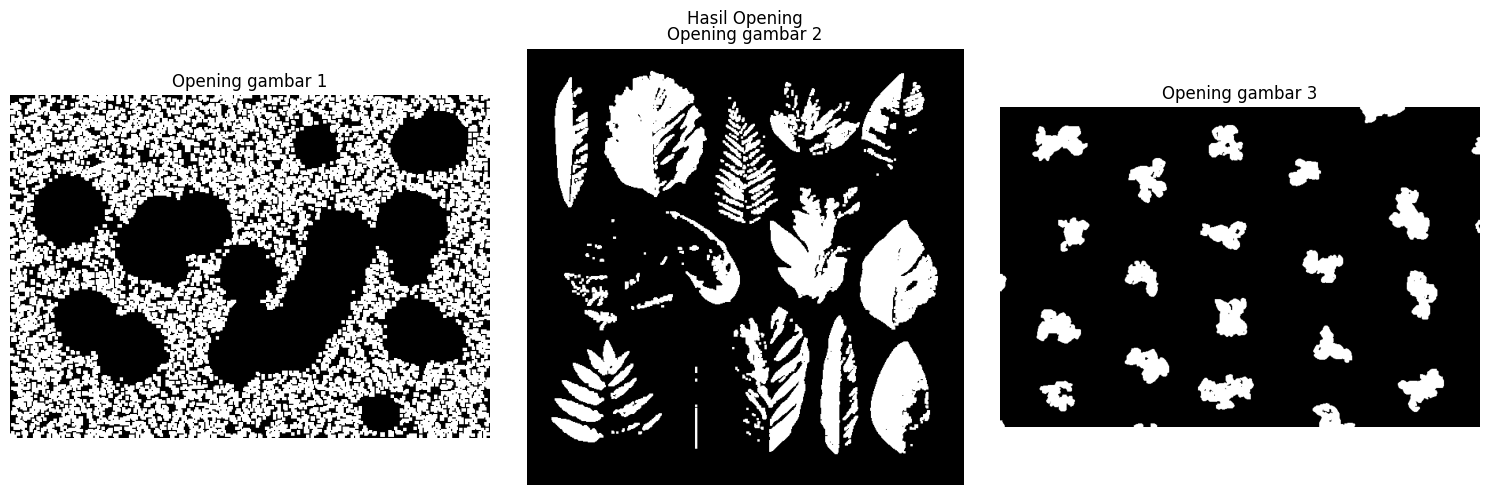

In [67]:
def opening(gambar):
    hasil_erosi = erosi(gambar)
    hasil_opening = dilasi(hasil_erosi)
    return hasil_opening


hasil_opening_1 = opening(hasil_segmentasi_1)
hasil_opening_2 = opening(hasil_segmentasi_2)
hasil_opening_3 = opening(hasil_segmentasi_3)

tampilkan_tiga(
    hasil_opening_1, hasil_opening_2, hasil_opening_3,
    "Hasil Opening",
    "Opening gambar 1", "Opening gambar 2", "Opening gambar 3"
)

## Operasi closing

Closing adalah dilation yang dilanjutkan dengan erosion.

Rumus:

$
A\bullet B=(A\oplus B)\ominus B
$

Closing membantu menutup lubang kecil atau celah sempit pada objek.

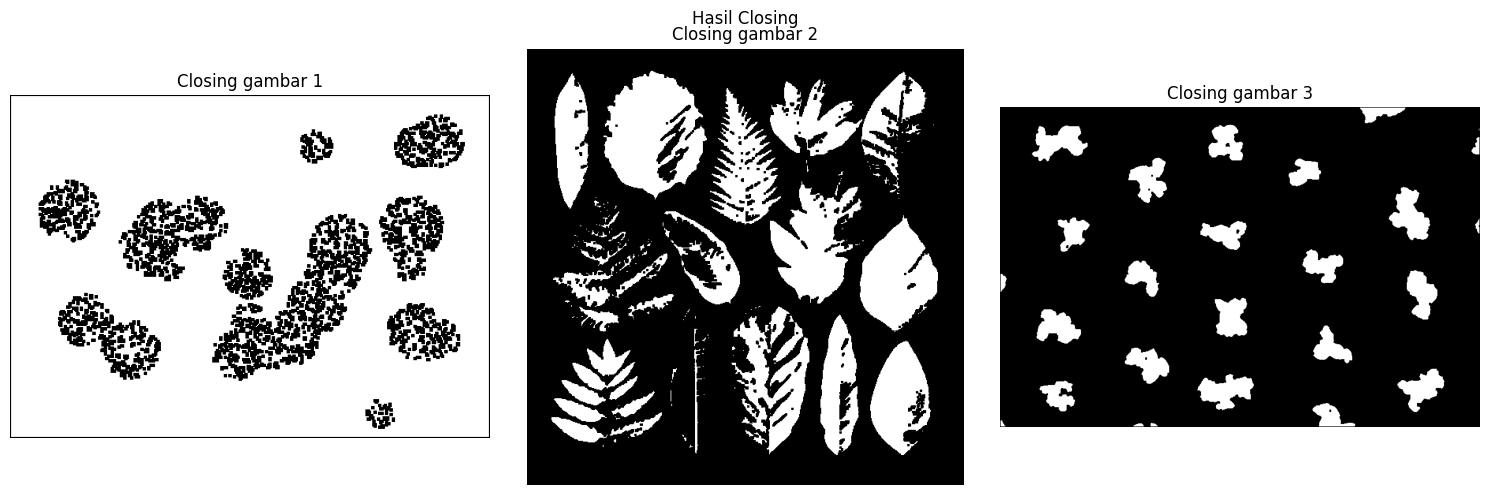

In [68]:
def closing(gambar):
    hasil_dilasi = dilasi(gambar)
    hasil_closing = erosi(hasil_dilasi)
    return hasil_closing


hasil_closing_1 = closing(hasil_segmentasi_1)
hasil_closing_2 = closing(hasil_segmentasi_2)
hasil_closing_3 = closing(hasil_segmentasi_3)

tampilkan_tiga(
    hasil_closing_1, hasil_closing_2, hasil_closing_3,
    "Hasil Closing",
    "Closing gambar 1", "Closing gambar 2", "Closing gambar 3"
)

## Menggabungkan opening dan closing

Opening dilakukan lebih dulu untuk mengurangi noise. Setelah itu, closing membantu menutup lubang atau celah kecil.

$
\text{Hasil akhir}=(A\circ B)\bullet B
$

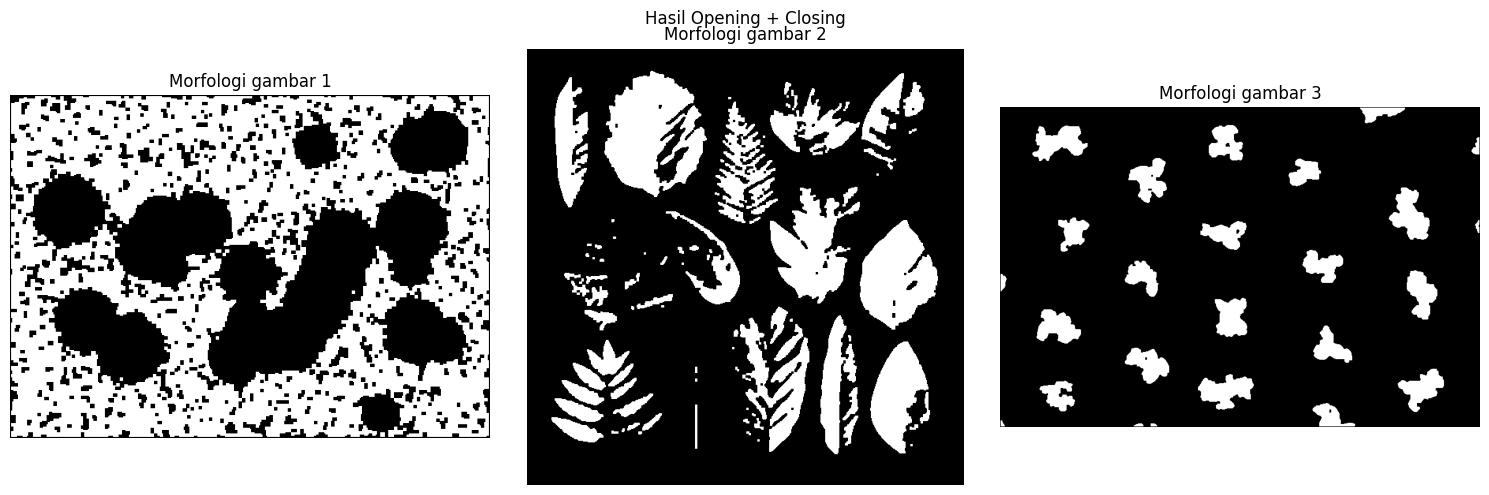

In [69]:
hasil_morfologi_1 = closing(hasil_opening_1)
hasil_morfologi_2 = closing(hasil_opening_2)
hasil_morfologi_3 = closing(hasil_opening_3)

tampilkan_tiga(
    hasil_morfologi_1, hasil_morfologi_2, hasil_morfologi_3,
    "Hasil Opening + Closing",
    "Morfologi gambar 1", "Morfologi gambar 2", "Morfologi gambar 3"
)

## Perbandingan sebelum dan sesudah morfologi

Setiap baris menunjukkan satu gambar:
- Kolom kiri: hasil thresholding tanpa morfologi.
- Kolom kanan: hasil setelah opening dan closing.


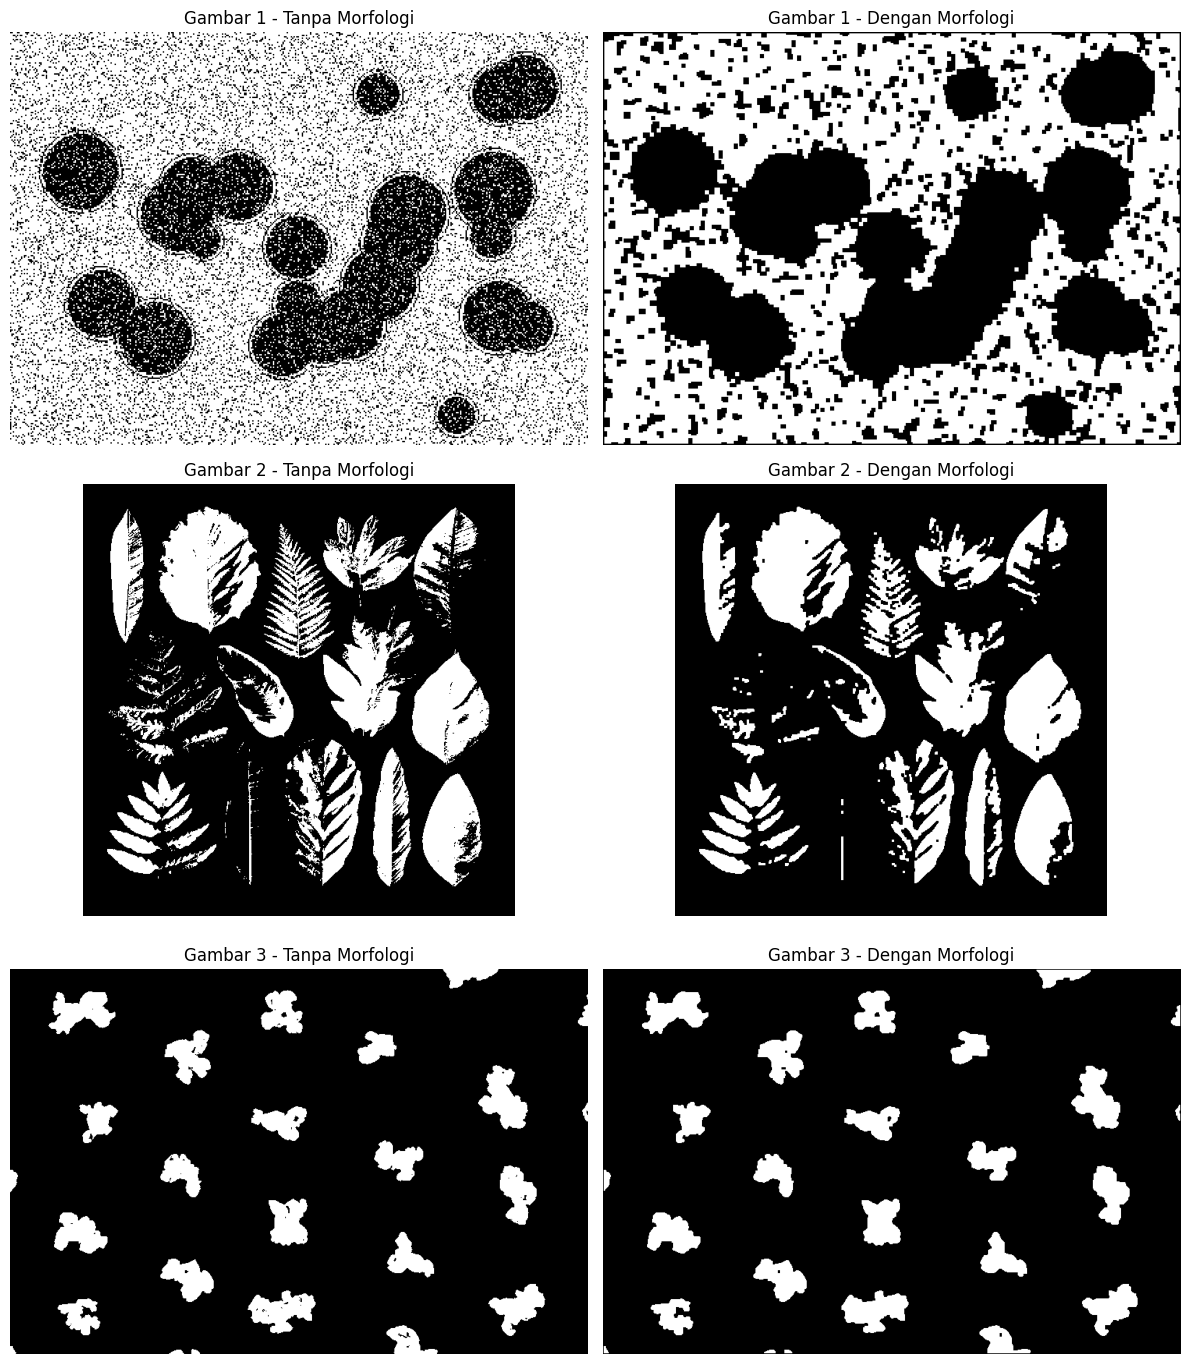

In [70]:
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

data_perbandingan = [
    (hasil_segmentasi_1, hasil_morfologi_1, "Gambar 1"),
    (hasil_segmentasi_2, hasil_morfologi_2, "Gambar 2"),
    (hasil_segmentasi_3, hasil_morfologi_3, "Gambar 3")
]

for i, (awal, akhir, nama) in enumerate(data_perbandingan):
    axes[i, 0].imshow(awal, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(nama + " - Tanpa Morfologi")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(akhir, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(nama + " - Dengan Morfologi")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Menyimpan semua hasil

Hasil grayscale, thresholding, dilation, erosion, opening, closing, dan gabungan morfologi dari ketiga gambar

In [71]:
def simpan_bmp(nama_file, gambar):
    tinggi = len(gambar)
    lebar = len(gambar[0])

    ukuran_baris = ((lebar * 3 + 3) // 4) * 4
    ukuran_data = ukuran_baris * tinggi
    ukuran_file = 54 + ukuran_data
    padding = ukuran_baris - lebar * 3

    header = bytearray()
    header.extend(b"BM")
    header.extend(ukuran_file.to_bytes(4, "little"))
    header.extend((0).to_bytes(2, "little"))
    header.extend((0).to_bytes(2, "little"))
    header.extend((54).to_bytes(4, "little"))

    header.extend((40).to_bytes(4, "little"))
    header.extend(lebar.to_bytes(4, "little", signed=True))
    header.extend(tinggi.to_bytes(4, "little", signed=True))
    header.extend((1).to_bytes(2, "little"))
    header.extend((24).to_bytes(2, "little"))
    header.extend((0).to_bytes(4, "little"))
    header.extend(ukuran_data.to_bytes(4, "little"))
    header.extend((2835).to_bytes(4, "little", signed=True))
    header.extend((2835).to_bytes(4, "little", signed=True))
    header.extend((0).to_bytes(4, "little"))
    header.extend((0).to_bytes(4, "little"))

    piksel = bytearray()

    for y in range(tinggi - 1, -1, -1):
        for x in range(lebar):
            nilai = gambar[y][x]
            piksel.extend(bytes((nilai, nilai, nilai)))

        for _ in range(padding):
            piksel.append(0)

    with open(nama_file, "wb") as file:
        file.write(header)
        file.write(piksel)


semua_hasil = [
    ("gambar1", gambar_abu_1, hasil_segmentasi_1, hasil_dilasi_1,
     hasil_erosi_1, hasil_opening_1, hasil_closing_1, hasil_morfologi_1),
    ("gambar2", gambar_abu_2, hasil_segmentasi_2, hasil_dilasi_2,
     hasil_erosi_2, hasil_opening_2, hasil_closing_2, hasil_morfologi_2),
    ("gambar3", gambar_abu_3, hasil_segmentasi_3, hasil_dilasi_3,
     hasil_erosi_3, hasil_opening_3, hasil_closing_3, hasil_morfologi_3)
]

nama_tahap = [
    "grayscale", "thresholding", "dilation", "erosion",
    "opening", "closing", "morfologi"
]

for data in semua_hasil:
    nama_gambar = data[0]
    daftar_gambar = data[1:]

    for tahap, hasil in zip(nama_tahap, daftar_gambar):
        simpan_bmp(nama_gambar + "_" + tahap + ".bmp", hasil)

print("Semua hasil dari tiga gambar berhasil disimpan.")

Semua hasil dari tiga gambar berhasil disimpan.


## Ringkasan jumlah piksel putih

Jumlah piksel putih dihitung sebelum dan sesudah morfologi. Angka ini menunjukkan perubahan luas area objek, tetapi tidak otomatis menentukan hasil mana yang paling baik. Tetap perhatikan gambar pada bagian perbandingan.

In [72]:
def hitung_piksel_putih(gambar):
    jumlah = 0

    for y in range(len(gambar)):
        for x in range(len(gambar[0])):
            if gambar[y][x] == 255:
                jumlah += 1

    return jumlah


data_ringkasan = [
    ("Gambar 1", hasil_segmentasi_1, hasil_morfologi_1),
    ("Gambar 2", hasil_segmentasi_2, hasil_morfologi_2),
    ("Gambar 3", hasil_segmentasi_3, hasil_morfologi_3)
]

for nama, awal, akhir in data_ringkasan:
    print(nama)
    print("  Sebelum morfologi:", hitung_piksel_putih(awal))
    print("  Sesudah morfologi:", hitung_piksel_putih(akhir))

Gambar 1
  Sebelum morfologi: 84620
  Sesudah morfologi: 69768
Gambar 2
  Sebelum morfologi: 79499
  Sesudah morfologi: 74335
Gambar 3
  Sebelum morfologi: 43802
  Sesudah morfologi: 43772


## Kesimpulan

Thresholding memisahkan objek dan latar belakang berdasarkan intensitas piksel. Hasil awalnya masih bisa mengandung noise atau lubang kecil.

Morphological processing membantu memperbaiki hasil segmentasi. Dilation memperbesar objek, erosion memperkecil objek, opening mengurangi noise kecil, dan closing membantu menutup lubang atau celah.
